# MiBici | Refactorización funcional

Pipeline de lectura, limpieza B, separación temporal (train, validation y test), análisis exploratorio y registro en MLflow. Todas las etapas se ejecutan desde `main()`; las funciones pueden trasladarse después a módulos `.py`.

## 1. Setup

Configuración centralizada para repetir las pruebas sin modificar los archivos originales.

In [19]:
import codecs
import hashlib
import json
import re
import sys
import time
from collections import Counter
from contextlib import ExitStack, contextmanager
from datetime import datetime, timezone
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from IPython.display import display
from pandas.testing import assert_frame_equal

try:
    import resource  # Solo existe en Linux y WSL
except ImportError:
    resource = None


def locate_project_root(start: Path) -> Path:
    """Buscar la raíz del repositorio sin importar módulos propios."""
    for directory in (start, *start.parents):
        if (directory / 'pyproject.toml').is_file() and (directory / 'data' / 'raw').is_dir():
            return directory
    raise FileNotFoundError('No se encontró pyproject.toml y data/raw en los directorios superiores.')


STUDY_START = pd.Timestamp('2020-01-01')
STUDY_END = pd.Timestamp('2026-10-01')
# Cortes de la separación temporal; cada fecha es el inicio del conjunto siguiente
TRAIN_END = pd.Timestamp('2025-01-01')
VALIDATION_END = pd.Timestamp('2026-01-01')
SPLIT_PERIODS = {
    'train': (STUDY_START, TRAIN_END),
    'validation': (TRAIN_END, VALIDATION_END),
    'test': (VALIDATION_END, STUDY_END),
}
MLFLOW_EXPERIMENT = 'MiBici'
EXPECTED_MONTHS = pd.period_range('2020-01', '2026-09', freq='M')
CHUNK_SIZE = 50_000
RUN_ALL_FILES = True  # True: 81 CSV; False: prueba con dos meses
RUN_LABEL = 'MiBici optimizado'
SAVE_TRIPS = True       # Escritura Parquet por bloques
EXCLUDED_STATIONS = frozenset({407, 124, 405})
VALID_GENDERS = frozenset({'M', 'F'})
MIN_AGE, MAX_AGE = 10, 100
DATETIME_FORMAT = '%Y-%m-%d %H:%M:%S'
ALTERNATIVE_DATETIME_FORMAT = '%d/%m/%Y %H:%M'
COLUMN_MAPPING = {'A}äe_nacimiento': 'Año_de_nacimiento'}
REQUIRED_COLUMNS = (
    'Viaje_Id', 'Usuario_Id', 'Genero', 'Año_de_nacimiento',
    'Inicio_del_viaje', 'Fin_del_viaje', 'Origen_Id', 'Destino_Id',
)
INTEGER_COLUMNS = ('Viaje_Id', 'Usuario_Id', 'Origen_Id', 'Destino_Id')
EXCLUSION_REASONS = (
    'Viaje_Id inválido', 'Viaje_Id duplicado', 'Inicio inválido',
    'Fuera del periodo', 'Origen inválido', 'Estación excluida',
)

## 2. Lectura y normalización

Validamos el inventario mensual y convertimos las columnas necesarias por bloques.

In [20]:
MONTHLY_NAME = re.compile(r'^datos_abiertos_(\d{4})_(\d{2})\.csv$', re.IGNORECASE)


def file_month(file_path: Path) -> pd.Period | None:
    """Obtener el mes indicado en el nombre de un archivo mensual."""
    match = MONTHLY_NAME.fullmatch(file_path.name)
    if match is None:
        return None
    return pd.Period(f'{match.group(1)}-{match.group(2)}', freq='M')


def discover_monthly_files(raw_dir: Path) -> list[Path]:
    """Encontrar los CSV mensuales y rechazar meses repetidos."""
    monthly = {}
    for path in raw_dir.rglob('*.csv'):
        month = file_month(path)
        if month is None:
            continue
        if month in monthly:
            raise ValueError(f'Mes duplicado: {month}: {monthly[month]} y {path}')
        monthly[month] = path
    expected = set(EXPECTED_MONTHS)
    missing = sorted(expected - set(monthly))
    extra = sorted(set(monthly) - expected)
    if missing or extra:
        raise ValueError(f'Inventario incorrecto. Faltantes: {missing}; adicionales: {extra}')
    return [monthly[month] for month in EXPECTED_MONTHS]


def read_csv_chunks(file_path: Path, chunk_size: int):
    """Select a verified encoding and read CSV records in bounded chunks."""
    if chunk_size < 1:
        raise ValueError('chunk_size debe ser positivo')
    encoding = 'utf-8'
    decoder = codecs.getincrementaldecoder(encoding)('strict')
    try:
        with file_path.open('rb') as source:
            for block in iter(lambda: source.read(1024 * 1024), b''):
                decoder.decode(block)
            decoder.decode(b'', final=True)
    except UnicodeDecodeError:
        encoding = 'cp1252'
    reader = pd.read_csv(
        file_path, encoding=encoding, dtype='string', chunksize=chunk_size
    )
    return reader, encoding

### 2.1. Normalización de tipos

Convertimos los identificadores, el año de nacimiento, el género y las fechas al tipo esperado sin modificar el bloque recibido.

In [21]:
INTEGER_PATTERN = re.compile(r'[+-]?\d+(?:\.0+)?\Z')
INT64_MIN, INT64_MAX = -(2**63), 2**63 - 1


def parse_integer(value):
    """Parse exact integer text without rounding large identifiers."""
    if pd.isna(value):
        return pd.NA
    text = str(value).strip()
    if not INTEGER_PATTERN.fullmatch(text):
        return pd.NA
    try:
        number = int(text.split('.')[0])
    except ValueError:
        return pd.NA
    return number if INT64_MIN <= number <= INT64_MAX else pd.NA


def normalize_integer_column(values: pd.Series) -> pd.Series:
    """Return a nullable Int64 series preserving the original index."""
    return pd.Series(pd.array([parse_integer(v) for v in values], dtype='Int64'), index=values.index)


def normalize_datetime_column(values: pd.Series) -> pd.Series:
    """Accept the two date formats identified in the original notebook."""
    primary = pd.to_datetime(values, format=DATETIME_FORMAT, errors='coerce')
    missing = primary.isna() & values.notna()
    if missing.any():
        primary.loc[missing] = pd.to_datetime(
            values.loc[missing], format=ALTERNATIVE_DATETIME_FORMAT, errors='coerce'
        )
    return primary


def normalize_chunk(chunk: pd.DataFrame) -> pd.DataFrame:
    """Normalize the eight trip columns without changing the input."""
    if not isinstance(chunk, pd.DataFrame):
        raise TypeError('chunk debe ser un DataFrame')
    result = chunk.rename(columns=COLUMN_MAPPING).copy()
    if not result.columns.is_unique:
        raise ValueError('Hay columnas repetidas después de normalizar encabezados')
    missing = set(REQUIRED_COLUMNS) - set(result.columns)
    if missing:
        raise ValueError(f'Faltan columnas: {sorted(missing)}')
    for column in INTEGER_COLUMNS:
        result[column] = normalize_integer_column(result[column])
    result['Año_de_nacimiento'] = pd.to_numeric(
        result['Año_de_nacimiento'], errors='coerce'
    ).astype('Float64')
    result['Genero'] = result['Genero'].astype('string')
    for column in ('Inicio_del_viaje', 'Fin_del_viaje'):
        result[column] = normalize_datetime_column(result[column])
    return result

## 3. Limpieza B y variables

Aplicamos las exclusiones acordadas, conservamos la trazabilidad de registros y generamos variables derivadas.

In [22]:
def classify_duration(duration_minutes: pd.Series) -> pd.Categorical:
    """Classify trip duration using the original seven categories."""
    categories = [
        'Muy corto', 'Corto', 'Habitual', 'Largo',
        'Muy largo', 'Prolongado', 'Extremo',
    ]
    values = pd.to_numeric(duration_minutes, errors='coerce').astype('float64').copy()
    values = values.mask(values < 0)
    values = values.mask(values == 180, np.nextafter(180.0, -np.inf))
    values = values.mask(values == 1440, np.nextafter(1440.0, -np.inf))
    return pd.cut(
        values, bins=[-np.inf, 1, 5, 15, 30, 180, 1440, np.inf],
        labels=categories, right=False,
    )


def add_trip_features(data: pd.DataFrame) -> pd.DataFrame:
    """Add trip duration, duration class and station relation."""
    result = data.copy()
    start = pd.to_datetime(result['Inicio_del_viaje'], errors='coerce')
    end = pd.to_datetime(result['Fin_del_viaje'], errors='coerce')
    duration = (end - start).dt.total_seconds().div(60).mask(lambda x: x < 0)
    result['duracion_minutos'] = duration
    result['categoria_duracion'] = classify_duration(duration)
    origin = result['Origen_Id'].astype('Int64')
    destination = result['Destino_Id'].astype('Int64')
    valid = origin.notna() & destination.notna()
    same = origin.eq(destination).fillna(False) & valid
    different = origin.ne(destination).fillna(False) & valid
    result['tipo_recorrido'] = pd.Series(pd.NA, index=result.index, dtype='string')
    result.loc[same, 'tipo_recorrido'] = 'Misma estación'
    result.loc[different, 'tipo_recorrido'] = 'Estaciones diferentes'
    return result


def clean_strategy_b(data: pd.DataFrame, seen_ids: set[int] | None = None):
    """Apply strategy B; return cleaned rows, counters and new unique IDs."""
    if not isinstance(data, pd.DataFrame):
        raise TypeError('data debe ser un DataFrame')
    if seen_ids is not None and not isinstance(seen_ids, set):
        raise TypeError('seen_ids debe ser set o None')
    missing = set(REQUIRED_COLUMNS) - set(data.columns)
    if missing:
        raise ValueError(f'Faltan columnas: {sorted(missing)}')
    previous = set() if seen_ids is None else seen_ids
    result = data.copy()
    trip_id = result['Viaje_Id'].astype('Int64')
    origin = result['Origen_Id'].astype('Int64')
    destination = result['Destino_Id'].astype('Int64')
    start = pd.to_datetime(result['Inicio_del_viaje'], errors='coerce')
    reason = pd.Series(pd.NA, index=result.index, dtype='string')
    invalid_id = (trip_id.isna() | trip_id.le(0)).fillna(True)
    reason.loc[invalid_id] = EXCLUSION_REASONS[0]
    # Buscar solo los IDs del bloque en el conjunto, sin convertir el conjunto completo
    ids = trip_id.to_numpy(dtype='int64', na_value=-1).tolist()
    in_previous = pd.Series([value in previous for value in ids], index=trip_id.index)
    duplicated = (trip_id.duplicated(keep='first') | in_previous).fillna(False)
    reason.loc[reason.isna() & duplicated] = EXCLUSION_REASONS[1]
    reason.loc[reason.isna() & start.isna()] = EXCLUSION_REASONS[2]
    outside = (start.lt(STUDY_START) | start.ge(STUDY_END)).fillna(False)
    reason.loc[reason.isna() & outside] = EXCLUSION_REASONS[3]
    invalid_origin = (origin.isna() | origin.le(0)).fillna(True)
    reason.loc[reason.isna() & invalid_origin] = EXCLUSION_REASONS[4]
    excluded = (origin.isin(EXCLUDED_STATIONS) | destination.isin(EXCLUDED_STATIONS)).fillna(False)
    reason.loc[reason.isna() & excluded] = EXCLUSION_REASONS[5]
    new_ids = set(trip_id.loc[~invalid_id & ~duplicated].dropna().astype('int64').tolist())
    cleaned = result.loc[reason.isna()].copy()
    gender = cleaned['Genero'].astype('string').str.strip().str.upper()
    valid_gender = gender.isin(VALID_GENDERS).fillna(False)
    cleaned['Genero'] = gender.where(valid_gender, 'No especificado')
    birth_year = pd.to_numeric(cleaned['Año_de_nacimiento'], errors='coerce')
    age = pd.to_datetime(cleaned['Inicio_del_viaje']).dt.year - birth_year
    invalid_birth = (birth_year.notna() & ((birth_year % 1 != 0) | age.lt(MIN_AGE) | age.gt(MAX_AGE))).fillna(False)
    cleaned['Año_de_nacimiento'] = birth_year.mask(invalid_birth).astype('Int64')
    summary = {
        'original_rows': len(result),
        'kept_rows': len(cleaned),
        'excluded_rows': int(reason.notna().sum()),
        **{key: int(reason.eq(key).sum()) for key in EXCLUSION_REASONS},
        'corrected_genders': int((~valid_gender).sum()),
        'corrected_birth_years': int(invalid_birth.sum()),
    }
    return cleaned, summary, new_ids


def count_hourly_demand(trips: pd.DataFrame) -> pd.Series:
    """Count trips by origin station and hour of departure."""
    if trips.empty:
        index = pd.MultiIndex.from_arrays([[], []], names=['Origen_Id', 'Hora'])
        return pd.Series([], index=index, dtype='int64', name='Cantidad_viajes')
    valid = (
        trips['Viaje_Id'].notna() & trips['Viaje_Id'].gt(0)
        & trips['Origen_Id'].notna() & trips['Origen_Id'].gt(0)
        & trips['Inicio_del_viaje'].notna()
        & trips['Inicio_del_viaje'].ge(STUDY_START)
        & trips['Inicio_del_viaje'].lt(STUDY_END)
    ).fillna(False)
    selected = trips.loc[valid, ['Origen_Id', 'Inicio_del_viaje']].copy()
    selected['Hora'] = selected['Inicio_del_viaje'].dt.floor('h')
    return selected.groupby(['Origen_Id', 'Hora']).size().rename('Cantidad_viajes')

## 4. Pruebas

Comprobamos límites, duplicados y reglas de limpieza antes de procesar archivos reales.

In [23]:
def make_test_rows() -> pd.DataFrame:
    return pd.DataFrame({
        'Viaje_Id': ['1', '2', '2', '3', '4', '5', '6', '7'],
        'Usuario_Id': ['101'] * 8,
        'Genero': ['M', None, None, 'F', 'M', 'F', 'M', 'F'],
        'Año_de_nacimiento': ['1995', None, None, '1990', '2000', '1985', '1900', '2000'],
        'Inicio_del_viaje': [f'2026-09-01 {hour:02d}:00:00' for hour in range(8, 16)],
        'Fin_del_viaje': [f'2026-09-01 {hour:02d}:20:00' for hour in range(8, 16)],
        'Origen_Id': ['10', '10', '10', '407', '20', None, '30', '40'],
        'Destino_Id': ['10', '15', '15', '25', '30', '40', '35', '45'],
    })


def run_behavior_tests():
    source = make_test_rows()
    untouched = source.copy(deep=True)
    first = normalize_chunk(source.iloc[:2])
    second = normalize_chunk(source.iloc[2:])
    seen = set()
    cleaned_1, summary_1, new_1 = clean_strategy_b(first, seen)
    seen.update(new_1)
    cleaned_2, summary_2, new_2 = clean_strategy_b(second, seen)
    seen.update(new_2)
    assert summary_1['kept_rows'] + summary_2['kept_rows'] == 5
    assert summary_2['Viaje_Id duplicado'] == 1
    assert summary_2['Estación excluida'] == 1
    assert summary_2['Origen inválido'] == 1
    assert int(count_hourly_demand(add_trip_features(cleaned_1)).sum()) == len(cleaned_1)
    assert_frame_equal(source, untouched)
    assert seen == {1, 2, 3, 4, 5, 6, 7}
    durations = pd.Series([0, 1, 5, 15, 30, 180, 1440, 1441, -1])
    labels = classify_duration(durations).astype('string').tolist()
    assert labels[:8] == [
        'Muy corto', 'Corto', 'Habitual', 'Largo', 'Muy largo',
        'Muy largo', 'Prolongado', 'Extremo',
    ] and pd.isna(labels[-1])
    assert normalize_integer_column(pd.Series(['9223372036854775807', '9223372036854775808'])).tolist()[0] == 9223372036854775807
    assert pd.isna(normalize_integer_column(pd.Series(['9223372036854775808'])).iloc[0])
    return 'Pruebas de comportamiento: correctas'

## 5. Procesamiento y almacenamiento

Procesamos cada CSV por bloques, registramos tiempos y escribimos viajes y demanda horaria en Parquet.

In [24]:
TRIP_PARQUET_SCHEMA = pa.schema([
    pa.field('Viaje_Id', pa.int64()),
    pa.field('Usuario_Id', pa.int64()),
    pa.field('Genero', pa.string()),
    pa.field('Año_de_nacimiento', pa.int64()),
    pa.field('Inicio_del_viaje', pa.timestamp('ns')),
    pa.field('Fin_del_viaje', pa.timestamp('ns')),
    pa.field('Origen_Id', pa.int64()),
    pa.field('Destino_Id', pa.int64()),
    pa.field('duracion_minutos', pa.float64()),
    pa.field('categoria_duracion', pa.string()),
    pa.field('tipo_recorrido', pa.string()),
])


@contextmanager
def timed(times: Counter, stage: str):
    """Sumar al contador el tiempo que tarda una etapa."""
    start = time.perf_counter()
    try:
        yield
    finally:
        times[stage] += time.perf_counter() - start


def check_counts(summary, demand_total: int, label: str) -> None:
    """Comprobar que registros, motivos de exclusión y demanda concilien."""
    if summary['original_rows'] != summary['kept_rows'] + summary['excluded_rows']:
        raise AssertionError(f'{label}: los registros no concilian')
    if sum(summary[key] for key in EXCLUSION_REASONS) != summary['excluded_rows']:
        raise AssertionError(f'{label}: los motivos de exclusión no concilian')
    if demand_total != summary['kept_rows']:
        raise AssertionError(f'{label}: la demanda no coincide con los viajes conservados')


def as_arrow_table(trips: pd.DataFrame) -> pa.Table:
    """Convertir los viajes transformados al esquema Parquet."""
    selected = trips.loc[:, TRIP_PARQUET_SCHEMA.names].copy()
    for column in ('Genero', 'categoria_duracion', 'tipo_recorrido'):
        selected[column] = selected[column].astype('string')
    return pa.Table.from_pandas(
        selected, schema=TRIP_PARQUET_SCHEMA, preserve_index=False, safe=True
    )


def merge_hourly(target: Counter, hourly: pd.Series) -> None:
    """Acumular conteos por estación y hora sin conservar los viajes."""
    target.update({(int(station), hour.isoformat()): int(value)
                   for (station, hour), value in hourly.items()})


def process_file(file_path: Path, chunk_size: int, seen_ids: set[int],
                 output_dir: Path, save_trips: bool = True):
    """Procesar un CSV por bloques, medir cada etapa y escribir un Parquet."""
    times = Counter()
    totals = Counter()
    hourly_totals = Counter()
    output_path = output_dir / f'{file_path.stem}.parquet'
    writer = None
    chunks = 0
    file_start = time.perf_counter()
    with timed(times, 'Apertura CSV'):
        reader, encoding = read_csv_chunks(file_path, chunk_size)
    chunk_iterator = iter(reader)
    try:
        while True:
            with timed(times, 'Lectura CSV'):
                raw = next(chunk_iterator, None)
            if raw is None:
                break
            chunks += 1
            with timed(times, 'Normalización'):
                normalized = normalize_chunk(raw)
            with timed(times, 'Limpieza B'):
                cleaned, summary, new_ids = clean_strategy_b(normalized, seen_ids)
            with timed(times, 'Variables'):
                trips = add_trip_features(cleaned)
            with timed(times, 'Demanda horaria'):
                hourly = count_hourly_demand(trips)
            check_counts(summary, int(hourly.sum()), f'{file_path.name}, bloque {chunks}')
            with timed(times, 'Escritura Parquet'):
                if save_trips:
                    if writer is None:
                        writer = pq.ParquetWriter(
                            output_path, TRIP_PARQUET_SCHEMA, compression='snappy'
                        )
                    writer.write_table(as_arrow_table(trips))
            with timed(times, 'Actualización IDs'):
                seen_ids.update(new_ids)
            with timed(times, 'Acumulación horaria'):
                merge_hourly(hourly_totals, hourly)
            totals.update(summary)
            del raw, normalized, cleaned, trips, hourly
    finally:
        if writer is not None:
            writer.close()
    times['Tiempo total'] = time.perf_counter() - file_start
    if writer is not None and pq.ParquetFile(output_path).metadata.num_rows != totals['kept_rows']:
        raise AssertionError('El Parquet no coincide con los viajes conservados')
    return {
        'file': file_path.name, 'encoding': encoding, 'chunks': chunks,
        'summary': dict(totals), 'timings': dict(times),
        'hourly': hourly_totals, 'parquet': str(output_path) if writer is not None else None,
    }

### 5.1. Prueba de integración con CSV temporales

Comprobamos la lectura, los duplicados entre archivos, la escritura Parquet y la conciliación de la demanda con dos archivos pequeños antes de usar los datos reales.

In [25]:
def run_integration_test():
    with TemporaryDirectory(prefix='mibici_v1_test_') as directory:
        root = Path(directory)
        input_dir = root / 'input'
        output_dir = root / 'output'
        input_dir.mkdir()
        output_dir.mkdir()
        rows = make_test_rows()
        first_path = input_dir / 'datos_abiertos_2026_08.csv'
        second_path = input_dir / 'datos_abiertos_2026_09.csv'
        rows.iloc[:2].to_csv(first_path, index=False)
        rows.iloc[2:].to_csv(second_path, index=False)
        seen = set()
        a = process_file(first_path, 2, seen, output_dir)
        b = process_file(second_path, 2, seen, output_dir)
        assert a['summary']['kept_rows'] + b['summary']['kept_rows'] == 5
        assert b['summary']['Viaje_Id duplicado'] == 1
        assert pq.ParquetFile(a['parquet']).metadata.num_rows == 2
        assert pq.ParquetFile(b['parquet']).metadata.num_rows == 3
        assert sum(a['hourly'].values()) + sum(b['hourly'].values()) == 5
        assert len(seen) == 7
    return 'Prueba de integración: correcta'

## 6. Ejecución por archivos y reportes

`process_dataset` procesa los archivos seleccionados, valida los conteos y guarda las tablas y métricas de la ejecución sin modificar los CSV originales.

In [26]:
def process_dataset(selected_files, report_dir, chunk_size, save_trips, run_all_files, run_label):
    """Procesar los CSV mensuales, validar los conteos y guardar los reportes."""
    if not selected_files:
        raise ValueError('No hay archivos seleccionados')
    report_dir.mkdir(parents=True, exist_ok=False)
    trips_dir = report_dir / 'trips'
    trips_dir.mkdir()
    seen_ids = set()
    all_hourly = Counter()
    all_summaries = Counter()
    file_rows = []
    timing_rows = []
    run_started = datetime.now(timezone.utc).isoformat()
    run_start = time.perf_counter()

    for file_number, file_path in enumerate(selected_files, start=1):
        file_start = time.perf_counter()
        file_result = process_file(file_path, chunk_size, seen_ids, trips_dir, save_trips)
        all_summaries.update(file_result['summary'])
        all_hourly.update(file_result['hourly'])
        file_rows.append({'archivo': file_result['file'], 'bloques': file_result['chunks'],
                          'codificacion': file_result['encoding'], **file_result['summary']})
        timing_rows.append({'archivo': file_result['file'], **file_result['timings']})
        print(f'{file_number:02d}/{len(selected_files):02d} {file_path.name}: '
              f"{file_result['summary']['original_rows']:,} leídos, "
              f"{file_result['summary']['kept_rows']:,} conservados, "
              f'{time.perf_counter() - file_start:.1f} s')
    elapsed = time.perf_counter() - run_start
    peak_rss_kib = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss if resource else None

    file_summary = pd.DataFrame(file_rows)
    timing_summary = pd.DataFrame(timing_rows)
    hourly_output = pd.DataFrame(
        [(station, hour, count) for (station, hour), count in all_hourly.items()],
        columns=['Origen_Id', 'Hora', 'Cantidad_viajes'],
    ).sort_values(['Origen_Id', 'Hora']).reset_index(drop=True)
    if not hourly_output.empty:
        hourly_output['Hora'] = pd.to_datetime(hourly_output['Hora'])

    # Validar las tablas que se van a guardar antes de escribir los reportes
    check_counts(file_summary.sum(numeric_only=True),
                 int(hourly_output['Cantidad_viajes'].sum()), 'Ejecución completa')

    file_summary.to_csv(report_dir / 'file_summary.csv', index=False)
    timing_summary.to_csv(report_dir / 'timing_summary.csv', index=False)
    hourly_output.to_parquet(report_dir / 'hourly_demand.parquet', index=False)
    manifest = {
        'version': run_label, 'started_utc': run_started,
        'finished_utc': datetime.now(timezone.utc).isoformat(),
        'chunk_size': chunk_size, 'files_expected': len(EXPECTED_MONTHS),
        'files_processed': len(selected_files), 'full_period': run_all_files,
        'rows': dict(all_summaries), 'elapsed_seconds': elapsed,
        'process_peak_rss_kib': peak_rss_kib,
        'unique_trip_ids_seen': len(seen_ids),
        'python': sys.version.split()[0], 'pandas': pd.__version__, 'pyarrow': pa.__version__,
        'note': 'ru_maxrss mide el pico RSS del proceso en Linux; incluye otras operaciones del kernel.',
    }
    (report_dir / 'manifest.json').write_text(
        json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8'
    )
    print('Archivos procesados:', len(selected_files))
    print('Filas leídas:', f"{all_summaries['original_rows']:,}")
    print('Viajes conservados:', f"{all_summaries['kept_rows']:,}")
    print('Demanda horaria:', f'{sum(all_hourly.values()):,}')
    print('Tiempo total:', f'{elapsed:.2f} s')
    if peak_rss_kib is not None and sys.platform.startswith('linux'):
        print('Memoria pico del proceso (RSS):', f'{peak_rss_kib / 1024:.1f} MiB')
    print('Reportes:', report_dir)
    print(file_summary.to_string(index=False))
    return {
        'file_summary': file_summary, 'timing_summary': timing_summary,
        'totals': all_summaries, 'report_dir': report_dir,
    }

## 7. Dataset de modelado y separación temporal

`complete_station_hours` completa con cero las horas sin viajes de cada estación y genera `hourly_complete.parquet`, la tabla de modelado: una fila por estación y hora, con `Cantidad_viajes` como objetivo. `split_dataset` la separa por fecha, sin mezclar observaciones:

| Conjunto | Periodo | Uso |
|---|---|---|
| train | enero 2020 – diciembre 2024 | Entrenamiento y EDA |
| validation | enero – diciembre 2025 | Comparar modelos y ajustar parámetros |
| test | enero – septiembre 2026 | Evaluación final |

`split_dataset` lee por bloques y comprueba que las claves `(Origen_Id, Hora)` estén ordenadas y sin repetir, que los tres conjuntos sumen las filas y los viajes de la tabla completa y, en una ejecución con los 81 CSV, que ningún conjunto quede vacío. Guarda `train.parquet`, `validation.parquet`, `test.parquet` y `split_summary.csv`, con el SHA-256 de cada archivo como versión del dataset.

**Limitación documentada.** El relleno con ceros va del primer al último viaje de cada estación en todo el periodo. Si una estación no tiene viajes al final de 2024 y vuelve a tenerlos en 2026, sus ceros de train dependen de un dato de test.

In [27]:
COMPLETE_SCHEMA = pa.schema([
    pa.field('Origen_Id', pa.int32()),
    pa.field('Hora', pa.timestamp('ns')),
    pa.field('Cantidad_viajes', pa.int32()),
])


def fill_station_hours(station_id: int, station: pd.DataFrame) -> pa.Table:
    """Completar con ceros las horas de una estación entre su primer y último viaje."""
    hours = pd.date_range(station['Hora'].min(), station['Hora'].max(), freq='h')
    values = station.set_index('Hora')['Cantidad_viajes'].reindex(hours, fill_value=0)
    return pa.Table.from_pydict({
        'Origen_Id': np.full(len(hours), station_id, dtype=np.int32),
        'Hora': hours.to_numpy(),
        'Cantidad_viajes': values.to_numpy(dtype=np.int32),
    }, schema=COMPLETE_SCHEMA)


def complete_station_hours(observed_path: Path, complete_path: Path) -> None:
    """Escribir la tabla completa procesando una estación a la vez."""
    pending = pd.DataFrame()
    with pq.ParquetWriter(complete_path, COMPLETE_SCHEMA, compression='zstd') as writer:
        for batch in pq.ParquetFile(observed_path).iter_batches(batch_size=100_000):
            block = pd.concat([pending, batch.to_pandas()], ignore_index=True)
            # La última estación del lote puede continuar en el siguiente
            if block.empty:
                continue
            last_station = block['Origen_Id'].iloc[-1]
            ready = block.loc[block['Origen_Id'] != last_station]
            pending = block.loc[block['Origen_Id'] == last_station]
            for station_id, station in ready.groupby('Origen_Id', sort=True):
                writer.write_table(fill_station_hours(station_id, station))
        if not pending.empty:
            writer.write_table(fill_station_hours(int(pending['Origen_Id'].iloc[0]), pending))


def check_sorted_keys(data: pd.DataFrame, previous: tuple | None) -> None:
    """Comprobar que las claves (Origen_Id, Hora) estén ordenadas y no se repitan."""
    stations = data['Origen_Id'].to_numpy(dtype=np.int64)
    hours = data['Hora'].to_numpy()
    if previous is not None:
        # Incluir la última clave del bloque anterior para revisar la unión entre bloques
        stations = np.r_[previous[0], stations]
        hours = np.r_[np.datetime64(previous[1], 'ns'), hours]
    station_step = np.diff(stations)
    hour_step = np.diff(hours)
    ordered = (station_step > 0) | ((station_step == 0) & (hour_step > np.timedelta64(0, 'ns')))
    if not ordered.all():
        raise ValueError('Hay claves (Origen_Id, Hora) repetidas o fuera de orden')


def file_sha256(path: Path) -> str:
    """Calcular el SHA-256 de un archivo para identificar la versión del dataset."""
    digest = hashlib.sha256()
    with open(path, 'rb') as file:
        for block in iter(lambda: file.read(1 << 20), b''):
            digest.update(block)
    return digest.hexdigest()


def split_dataset(complete_path: Path, output_dir: Path, total_trips: int,
                  run_all_files: bool) -> pd.DataFrame:
    """Separar la demanda estación-hora por fecha y escribir un Parquet por conjunto."""
    output_dir.mkdir()
    rows, trips = Counter(), Counter()
    first_hour, last_hour = {}, {}
    previous = None
    with ExitStack() as stack:
        writers = {
            name: stack.enter_context(pq.ParquetWriter(
                output_dir / f'{name}.parquet', COMPLETE_SCHEMA, compression='zstd'))
            for name in SPLIT_PERIODS
        }
        for batch in pq.ParquetFile(complete_path).iter_batches(batch_size=100_000):
            data = batch.to_pandas()
            check_sorted_keys(data, previous)
            previous = (data['Origen_Id'].iloc[-1], data['Hora'].iloc[-1])
            for name, (start, end) in SPLIT_PERIODS.items():
                selected = data.loc[data['Hora'].ge(start) & data['Hora'].lt(end)]
                if selected.empty:
                    continue
                writers[name].write_table(
                    pa.Table.from_pandas(selected, schema=COMPLETE_SCHEMA, preserve_index=False))
                rows[name] += len(selected)
                trips[name] += int(selected['Cantidad_viajes'].sum())
                first_hour[name] = min(first_hour.get(name, selected['Hora'].min()), selected['Hora'].min())
                last_hour[name] = max(last_hour.get(name, selected['Hora'].max()), selected['Hora'].max())

    # Validar la separación antes de usar los conjuntos
    if sum(rows.values()) != pq.ParquetFile(complete_path).metadata.num_rows:
        raise ValueError('Hay filas fuera de los periodos de train, validation y test')
    if sum(trips.values()) != total_trips:
        raise ValueError('Los viajes de los conjuntos no coinciden con los viajes conservados')
    empty = [name for name in SPLIT_PERIODS if rows[name] == 0]
    if run_all_files and empty:
        raise ValueError(f'Conjuntos sin registros: {empty}')

    splits = pd.DataFrame([{
        'Conjunto': name, 'Inicio': start.date(), 'Fin_exclusivo': end.date(),
        'Filas': rows[name], 'Viajes': trips[name],
        'Primera_hora': first_hour.get(name), 'Ultima_hora': last_hour.get(name),
        'Archivo': str(output_dir / f'{name}.parquet'),
        'SHA256': file_sha256(output_dir / f'{name}.parquet'),
    } for name, (start, end) in SPLIT_PERIODS.items()]).set_index('Conjunto')
    splits.to_csv(output_dir / 'split_summary.csv')
    print(splits[['Inicio', 'Fin_exclusivo', 'Filas', 'Viajes', 'Primera_hora', 'Ultima_hora']].to_string())
    return splits

### 7.1. Prueba de la separación

Una tabla pequeña con horas justo antes y después de cada corte comprueba que cada fila caiga en su conjunto y que una clave repetida detenga la ejecución.

In [28]:
def run_split_test():
    """Probar los cortes de la separación con horas alrededor de cada fecha límite."""
    hours = pd.to_datetime(['2024-12-31 23:00', '2025-01-01 00:00',
                            '2025-12-31 23:00', '2026-01-01 00:00'])
    table = pd.DataFrame({
        'Origen_Id': np.full(4, 10, dtype=np.int32), 'Hora': hours,
        'Cantidad_viajes': np.array([1, 2, 3, 4], dtype=np.int32),
    })
    with TemporaryDirectory(prefix='mibici_split_test_') as directory:
        root = Path(directory)
        pq.write_table(pa.Table.from_pandas(table, schema=COMPLETE_SCHEMA, preserve_index=False),
                       root / 'complete.parquet')
        splits = split_dataset(root / 'complete.parquet', root / 'splits', 10, True)
        assert splits['Filas'].tolist() == [1, 2, 1]
        assert splits['Viajes'].tolist() == [1, 5, 4]
        assert pd.read_parquet(root / 'splits' / 'test.parquet')['Hora'].min() == VALIDATION_END
        # Una clave repetida debe detener la separación
        repeated = pd.concat([table, table.tail(1)], ignore_index=True)
        pq.write_table(pa.Table.from_pandas(repeated, schema=COMPLETE_SCHEMA, preserve_index=False),
                       root / 'repeated.parquet')
        try:
            split_dataset(root / 'repeated.parquet', root / 'splits_repeated', 14, True)
        except ValueError:
            pass
        else:
            raise AssertionError('La clave repetida no se detectó')
    return 'Prueba de separación: correcta'

## 8. Análisis exploratorio

El EDA usa solo el conjunto train (2020–2024), para que las decisiones del modelo no dependan de validation ni de test. Los resúmenes se calculan mediante lectura por bloques.

In [29]:
def demand_summary(complete_path: Path) -> dict:
    """Collect EDA statistics in one streaming pass over complete station-hours."""
    totals = {name: Counter() for name in ('hour', 'weekday', 'station', 'weekday_hour', 'station_hour')}
    counts = {name: Counter() for name in totals}
    hist = Counter()
    weekday_hist = [Counter() for _ in range(7)]
    station_hist = {}
    maximum = Counter()
    # Guardar únicamente los 20 registros de mayor demanda
    top = pd.DataFrame({
        'Origen_Id': pd.Series(dtype='int32'),
        'Hora': pd.Series(dtype='datetime64[ns]'),
        'Cantidad_viajes': pd.Series(dtype='int32'),
    })
    keys = {
        'hour': ['hour'], 'weekday': ['weekday'], 'station': ['Origen_Id'],
        'weekday_hour': ['weekday', 'hour'], 'station_hour': ['Origen_Id', 'hour'],
    }
    for batch in pq.ParquetFile(complete_path).iter_batches(batch_size=100_000):
        data = batch.to_pandas()
        data['hour'] = data['Hora'].dt.hour
        data['weekday'] = data['Hora'].dt.dayofweek
        for name, columns in keys.items():
            grouped = data.groupby(columns)['Cantidad_viajes'].agg(['sum', 'count'])
            totals[name].update(grouped['sum'].to_dict())
            counts[name].update(grouped['count'].to_dict())
        hist.update(data['Cantidad_viajes'].value_counts().to_dict())
        for day, group in data.groupby('weekday'):
            weekday_hist[day].update(group['Cantidad_viajes'].value_counts().to_dict())
        for station_id, group in data.groupby('Origen_Id'):
            maximum[int(station_id)] = max(maximum[int(station_id)], int(group['Cantidad_viajes'].max()))
            station_hist.setdefault(int(station_id), Counter()).update(
                group['Cantidad_viajes'].value_counts().to_dict()
            )
        top = pd.concat([top, data.nlargest(20, 'Cantidad_viajes')[
            ['Origen_Id', 'Hora', 'Cantidad_viajes']
        ]], ignore_index=True).nlargest(20, 'Cantidad_viajes')
    result = {}
    for name in keys:
        frame = pd.DataFrame({
            'total': pd.Series(totals[name]), 'count': pd.Series(counts[name])
        })
        frame['mean'] = frame['total'] / frame['count']
        result[name] = frame.sort_index()
    result.update(hist=hist, weekday_hist=weekday_hist,
                  maximum=pd.Series(maximum), station_hist=station_hist,
                  top=top.reset_index(drop=True))
    return result


def hist_percentile(histogram: Counter, percentile: float) -> float:
    """Calculate a percentile with linear interpolation, without expanding records."""
    values = np.array(sorted(histogram))
    cumulative = np.cumsum([histogram[value] for value in values])
    position = (cumulative[-1] - 1) * percentile / 100
    lower, upper = int(np.floor(position)), int(np.ceil(position))
    low_value = values[np.searchsorted(cumulative, lower + 1)]
    high_value = values[np.searchsorted(cumulative, upper + 1)]
    return float(low_value + (high_value - low_value) * (position - lower))


def box_stats(histogram: Counter, label: str) -> dict:
    """Prepare an IQR boxplot from frequencies."""
    q1, median, q3 = [hist_percentile(histogram, p) for p in (25, 50, 75)]
    limit = q3 + 1.5 * (q3 - q1)
    return dict(label=label, q1=q1, med=median, q3=q3,
                whislo=min(histogram), whishi=max(v for v in histogram if v <= limit),
                fliers=[])

### 8.1. Visualizaciones

Las gráficas reutilizan funciones comunes para comparar distribución, comportamiento temporal y estaciones.

In [30]:
WEEKDAYS = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
MONTHS = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']


def finish_plot(ax, title, xlabel, ylabel, output_dir=None):
    """Apply shared labels and show a figure."""
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    plt.tight_layout()
    if output_dir is not None:
        output_dir.mkdir(parents=True, exist_ok=True)
        figure_number = len(list(output_dir.glob("figure_*.png"))) + 1
        ax.figure.savefig(output_dir / f"figure_{figure_number:02d}.png", dpi=150, bbox_inches="tight")
    plt.show()


def plot_series(values, title, xlabel, ylabel, kind='bar', horizontal=False,
                percentage=False, output_dir=None):
    """Plot a bar or line chart with optional percentage labels."""
    fig, ax = plt.subplots(figsize=(11, 5))
    if kind == 'line':
        ax.plot(values.index, values.values, marker='o', markersize=3)
    elif horizontal:
        bars = ax.barh(values.index.astype(str), values.values)
    else:
        bars = ax.bar(values.index.astype(str), values.values)
    if percentage and kind == 'bar':
        ax.bar_label(bars, fmt='%.1f%%', padding=3)
        ax.set_ylim(0, max(values.max() * 1.15, 1))
    ax.grid(axis='x' if horizontal else 'y', alpha=0.3)
    if not horizontal and kind == 'bar' and len(values) > 12:
        ax.tick_params(axis='x', rotation=45)
    finish_plot(ax, title, xlabel, ylabel, output_dir=output_dir)

def plot_heatmap(values, title, xlabel, ylabel, decimals=1, output_dir=None):
    """Plot a heatmap with numeric labels and missing-value handling."""
    fig, ax = plt.subplots(figsize=(13, 5))
    image = ax.imshow(values, aspect='auto', cmap='YlOrRd')
    ax.set_xticks(range(len(values.columns)), values.columns)
    ax.set_yticks(range(len(values.index)), values.index)
    if len(values.columns) == 12:
        ax.tick_params(axis='x', rotation=45)
    numeric = values.to_numpy(dtype=float)
    low, high = image.get_clim()
    midpoint = (low + high) / 2
    for row in range(numeric.shape[0]):
        for col in range(numeric.shape[1]):
            value = numeric[row, col]
            if np.isfinite(value):
                color = 'white' if value > midpoint else 'black'
                ax.text(col, row, f'{value:,.{decimals}f}',
                        ha='center', va='center', fontsize=7, color=color)
    fig.colorbar(image, ax=ax, label='Demanda promedio')
    finish_plot(ax, title, xlabel, ylabel, output_dir=output_dir)

def plot_demand_distribution(summary: dict, output_dir=None) -> None:
    """Show demand distribution by hour, weekday and station."""
    histogram = summary['hist']
    total = sum(histogram.values())
    ranges = [histogram[0], sum(histogram[i] for i in (1, 2)),
              sum(histogram[i] for i in (3, 4, 5)),
              sum(histogram[i] for i in range(6, 11)),
              sum(n for value, n in histogram.items() if value > 10)]
    distribution = pd.Series(np.array(ranges) / total * 100,
                             index=['0', '1–2', '3–5', '6–10', '>10'])
    plot_series(distribution, 'Distribución de demanda por estación-hora',
                'Viajes por estación-hora', 'Registros (%)', percentage=True, output_dir=output_dir)

    hour = summary['hour']['mean'].reindex(range(24))
    plot_series(hour, 'Demanda promedio por hora', 'Hora', 'Viajes por estación-hora', 'line', output_dir=output_dir)
    weekday = summary['weekday']['mean'].reindex(range(7))
    weekday.index = WEEKDAYS
    plot_series(weekday, 'Demanda promedio por día', 'Día', 'Viajes por estación-hora', output_dir=output_dir)

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.bxp([box_stats(hist, WEEKDAYS[i]) for i, hist in enumerate(summary['weekday_hist'])],
           showfliers=False)
    finish_plot(ax, 'Distribución de demanda por día', 'Día', 'Viajes por estación-hora', output_dir=output_dir)

    stations = summary['station']['mean'].sort_values()
    for title, values in [('Mayor', stations.tail(10)), ('Menor', stations.head(10))]:
        plot_series(values, f'{title} demanda promedio por estación',
                    'Viajes por estación-hora', 'Estación', horizontal=True, output_dir=output_dir)
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.boxplot(stations.to_numpy(), tick_labels=['Estaciones'], showfliers=False)
    finish_plot(ax, 'Distribución entre estaciones', '', 'Viajes por estación-hora', output_dir=output_dir)


def plot_demand_temporal(summary: dict, monthly_trips: pd.Series, output_dir=None) -> None:
    """Show monthly evolution and weekday-hour patterns."""
    monthly = monthly_trips.sort_index()
    dates = monthly.index.to_timestamp()
    plot_series(pd.Series(monthly.values, index=dates), 'Evolución mensual',
                'Mes', 'Cantidad de viajes', 'line', output_dir=output_dir)
    plot_series(pd.Series(monthly.pct_change().values * 100, index=dates),
                'Variación mensual', 'Mes', 'Variación (%)', 'line', output_dir=output_dir)

    day_hour = summary['weekday_hour']
    fig, ax = plt.subplots(figsize=(11, 5))
    for label, days in [('Lunes a viernes', range(5)), ('Fin de semana', range(5, 7))]:
        selected = day_hour.loc[list(days)].groupby(level=1)[['total', 'count']].sum()
        profile = selected['total'] / selected['count']
        ax.plot(profile.index, profile.values, marker='o', label=label)
    ax.legend()
    ax.set_xticks(range(24))
    finish_plot(ax, 'Días laborales y fines de semana', 'Hora', 'Viajes por estación-hora', output_dir=output_dir)
    heatmap = day_hour['mean'].unstack().reindex(index=range(7), columns=range(24))
    heatmap.index = WEEKDAYS
    plot_heatmap(heatmap, 'Demanda por día y hora', 'Hora', 'Día', output_dir=output_dir)

    season = pd.DataFrame({'year': monthly.index.year, 'month': monthly.index.month,
                           'daily': monthly.values / monthly.index.days_in_month})
    average = season.groupby('month')['daily'].mean().reindex(range(1, 13))
    average.index = MONTHS
    plot_series(average, 'Estacionalidad mensual', 'Mes', 'Viajes diarios', 'line', output_dir=output_dir)
    year_month = season.pivot(index='year', columns='month', values='daily').reindex(columns=range(1, 13))
    year_month.columns = MONTHS
    plot_heatmap(year_month, 'Demanda diaria por mes y año', 'Mes', 'Año', decimals=0, output_dir=output_dir)


def plot_demand_extremes(summary: dict, output_dir=None) -> None:
    """Show extreme station-hour demand and station profiles."""
    histogram = summary['hist']
    total = sum(histogram.values())
    q1, q3 = hist_percentile(histogram, 25), hist_percentile(histogram, 75)
    threshold = q3 + 1.5 * (q3 - q1)
    outliers = sum(n for value, n in histogram.items() if value > threshold)
    print(f'Atípicos: {outliers:,} de {total:,} ({outliers / total:.2%}); límite IQR: {threshold:.2f}')
    extreme = summary['top']['Cantidad_viajes'].iloc[::-1]
    extreme.index = extreme.index.astype(str)
    plot_series(extreme, '20 registros de mayor demanda', 'Viajes', 'Registro', horizontal=True, output_dir=output_dir)

    top_stations = summary['maximum'].nlargest(20).index
    comparison = pd.DataFrame({'Promedio': summary['station'].loc[top_stations, 'mean'],
                               'Máximo': summary['maximum'].loc[top_stations]})
    fig, ax = plt.subplots(figsize=(12, 6))
    comparison.plot.bar(ax=ax)
    ax.tick_params(axis='x', rotation=45)
    finish_plot(ax, 'Demanda promedio y máxima por estación', 'Estación', 'Viajes por estación-hora', output_dir=output_dir)

    station_hour = summary['station_hour']['mean'].unstack().reindex(columns=range(24))
    peaks = station_hour.idxmax(axis=1).value_counts().reindex(range(24), fill_value=0)
    plot_series(peaks, 'Hora pico por estación', 'Hora', 'Estaciones', output_dir=output_dir)
    fig, ax = plt.subplots(figsize=(12, 6))
    for station_id in summary['station']['total'].nlargest(10).index:
        ax.plot(station_hour.columns, station_hour.loc[station_id], label=str(station_id))
    ax.set_xticks(range(24))
    ax.legend(title='Estación', bbox_to_anchor=(1.02, 1), loc='upper left')
    finish_plot(ax, 'Patrones horarios de las 10 estaciones con más viajes',
                'Hora', 'Viajes por estación-hora', output_dir=output_dir)

### 8.2. Preparación del EDA

Calculamos los resúmenes de train una sola vez y comprobamos que coincidan con las filas y los viajes del conjunto. Las tablas y gráficas mensuales usan solo los meses de train.

In [31]:
def prepare_eda(results, splits: pd.DataFrame):
    """Calcular los resúmenes del EDA con el conjunto train."""
    train_path = Path(splits.loc['train', 'Archivo'])
    summary = demand_summary(train_path)
    monthly_trips = pd.Series({
        file_month(Path(file_name)): kept_rows
        for file_name, kept_rows in zip(results['file_summary']['archivo'],
                                        results['file_summary']['kept_rows'])
    })
    # El análisis mensual se limita a los meses de train
    monthly_trips = monthly_trips[monthly_trips.index < TRAIN_END.to_period('M')]
    assert sum(summary['hist'].values()) == splits.loc['train', 'Filas']
    assert sum(value * count for value, count in summary['hist'].items()) == splits.loc['train', 'Viajes']
    return summary, monthly_trips

## 9. Rendimiento y validación

Revisamos los tiempos de cada etapa y conciliamos viajes, demanda y archivos generados.

In [32]:
def show_performance(results, run_label):
    """Summarize elapsed time by pipeline stage."""
    stage_columns = [column for column in results["timing_summary"].columns
                     if column not in ('archivo', 'Tiempo total')]
    stage_totals = results["timing_summary"][stage_columns].sum().sort_values(ascending=False)
    performance_table = stage_totals.rename_axis('Etapa').reset_index(name='Segundos')
    performance_table['Porcentaje etapas'] = (
        performance_table['Segundos'] / performance_table['Segundos'].sum() * 100
        if performance_table['Segundos'].sum() else 0.0
    )
    print(performance_table.to_string(index=False))
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.barh(performance_table['Etapa'], performance_table['Segundos'])
    ax.invert_yaxis()
    ax.set_xlabel('Tiempo acumulado (s)')
    ax.set_title(f'{run_label} | Tiempo por etapa')
    plt.tight_layout()
    plt.show()

### 9.1. Cobertura de la ejecución

Las conciliaciones se comprobaron por bloque y sobre las tablas guardadas. Aquí solo se indica si la ejecución cubrió los 81 meses.

In [33]:
def show_coverage(selected_files, run_all_files, run_label):
    """Report whether the full study period was processed."""
    full_run = run_all_files and len(selected_files) == len(EXPECTED_MONTHS)
    print('Cobertura completa:', 'SÍ' if full_run else 'NO, prueba con dos meses')
    print(f'Cobertura de {run_label}:', '81 CSV seleccionados' if full_run else 'Prueba parcial')

### 9.2. Tablas y estadísticas del EDA
Se recuperan las tablas de las secciones 8.3 a 8.9.3 y se guardan como archivos CSV reutilizables.

In [34]:
def build_eda_tables(summary: dict, monthly_trips: pd.Series) -> dict:
    """Build EDA tables from existing summaries without rereading Parquet."""
    histogram = summary['hist']
    total = sum(histogram.values())
    mean = sum(value * count for value, count in histogram.items()) / total
    variance = sum(count * (value - mean) ** 2 for value, count in histogram.items())
    variance /= max(total - 1, 1)
    stats = pd.DataFrame({'Cantidad_viajes': {
        'count': total, 'mean': mean, 'std': np.sqrt(variance),
        **{f'{p}%': hist_percentile(histogram, p) for p in (0, 25, 50, 75, 90, 95, 99, 100)}
    }}).rename(index={'0%': 'min', '100%': 'max'})

    hourly = summary['hour'].reindex(range(24))
    hourly_table = pd.DataFrame({
        'Hora_del_dia': range(24), 'Promedio_viajes': hourly['mean'].to_numpy(),
        'Registros': hourly['count'].to_numpy()
    })
    weekday = summary['weekday'].reindex(range(7))
    weekday_table = pd.DataFrame({
        'Dia_semana': range(7), 'Nombre_dia': WEEKDAYS,
        'Promedio_viajes': weekday['mean'].to_numpy(),
        'Mediana_viajes': [hist_percentile(hist, 50) for hist in summary['weekday_hist']],
        'Registros': weekday['count'].to_numpy()
    })
    station = summary['station'].copy()
    station_table = pd.DataFrame({
        'Origen_Id': station.index,
        'Promedio_viajes': station['mean'].to_numpy(),
        'Mediana_viajes': [hist_percentile(summary['station_hist'][int(i)], 50) for i in station.index],
        'Total_viajes': station['total'].to_numpy(),
        'Horas_observadas': station['count'].to_numpy(),
        'Maximo_viajes': summary['maximum'].reindex(station.index).to_numpy()
    }).sort_values('Promedio_viajes', ascending=False).reset_index(drop=True)

    monthly = monthly_trips.sort_index().to_frame('Cantidad_viajes')
    monthly['Variacion_pct'] = monthly['Cantidad_viajes'].pct_change() * 100
    season = pd.DataFrame({
        'Mes_numero': monthly.index.month,
        'Año': monthly.index.year,
        'Promedio_diario': monthly['Cantidad_viajes'].to_numpy() / monthly.index.days_in_month
    })
    seasonal = season.groupby('Mes_numero')['Promedio_diario'].agg(
        Promedio_diario='mean', Mediana_diaria='median', Años_observados='count'
    ).reindex(range(1, 13))
    seasonal.index = MONTHS
    seasonal.index.name = 'Mes'

    day_hour = summary['weekday_hour']
    profiles = {}
    for label, days in [('Lunes a viernes', range(5)), ('Fin de semana', range(5, 7))]:
        group = day_hour.loc[list(days)].groupby(level=1)[['total', 'count']].sum()
        profiles[label] = (group['total'] / group['count']).reindex(range(24))
    day_type = pd.DataFrame(profiles)
    day_type.index.name = 'Hora_del_dia'

    q1, q3 = hist_percentile(histogram, 25), hist_percentile(histogram, 75)
    limit = q3 + 1.5 * (q3 - q1)
    outliers = sum(count for value, count in histogram.items() if value > limit)
    outlier_stats = pd.DataFrame({'Valor': {
        'Q1': q1, 'Q3': q3, 'IQR': q3 - q1, 'Limite_superior': limit,
        'Registros_analizados': total, 'Valores_atipicos': outliers,
        'Porcentaje_atipicos': outliers / total * 100
    }})

    station_outliers = []
    for station_id, station_hist in summary['station_hist'].items():
        a, b = hist_percentile(station_hist, 25), hist_percentile(station_hist, 75)
        station_limit = b + 1.5 * (b - a)
        count = sum(station_hist.values())
        extreme = sum(n for value, n in station_hist.items() if value > station_limit)
        station_outliers.append({
            'Origen_Id': station_id, 'Q1': a, 'Q3': b,
            'Limite_superior': station_limit, 'Valores_atipicos': extreme,
            'Porcentaje_atipicos': extreme / count * 100
        })
    station_extremes = station_table.set_index('Origen_Id').join(
        pd.DataFrame(station_outliers).set_index('Origen_Id')
    )
    station_extremes['Relacion_maximo_promedio'] = (
        station_extremes['Maximo_viajes'] /
        station_extremes['Promedio_viajes'].replace(0, np.nan)
    )
    station_extremes = station_extremes.sort_values('Maximo_viajes', ascending=False)

    station_hour = summary['station_hour']['mean'].unstack().reindex(columns=range(24))
    peak_hour = station_hour.idxmax(axis=1)
    peak_value = station_hour.max(axis=1)
    general_mean = summary['station']['mean'].reindex(station_hour.index)
    peaks = pd.DataFrame({
        'Origen_Id': station_hour.index, 'Hora_pico': peak_hour.to_numpy(),
        'Promedio_hora_pico': peak_value.to_numpy(),
        'Promedio_general': general_mean.to_numpy(),
        'Relacion_pico_promedio': (peak_value / general_mean.replace(0, np.nan)).to_numpy()
    }).sort_values('Origen_Id').reset_index(drop=True)

    return {
        'Estadísticas de demanda': stats,
        'Demanda por hora': hourly_table,
        'Demanda por día': weekday_table,
        'Demanda por estación': station_table,
        'Estadísticas mensuales': monthly.describe().round(2),
        'Meses con más viajes': monthly.nlargest(5, 'Cantidad_viajes'),
        'Meses con menos viajes': monthly.nsmallest(5, 'Cantidad_viajes'),
        'Días laborales y fines de semana': day_type,
        'Estacionalidad': seasonal,
        'Estadísticas de valores atípicos': outlier_stats,
        'Registros extremos': summary['top'],
        'Valores extremos por estación': station_extremes.head(20),
        'Horas pico por estación': peaks
    }


def show_eda_tables(tables: dict) -> None:
    """Display EDA tables in the same order as the original analysis."""
    for title, table in tables.items():
        print(f'\n{title}')
        display(table.round(2))


def save_eda_tables(tables: dict, output_dir: Path) -> None:
    """Guardar cada tabla del EDA en un CSV con el nombre de la tabla."""
    output_dir = output_dir / 'eda_tables'
    output_dir.mkdir(parents=True, exist_ok=True)
    for title, table in tables.items():
        file_name = re.sub(r'\W+', '_', title).strip('_').lower()
        table.to_csv(output_dir / f'{file_name}.csv', index=True)

## 10. Registro en MLflow

`log_to_mlflow` guarda cada ejecución en el experimento `MiBici`, con la base `mlflow.db` y los archivos en `mlruns/`, ambos en la raíz del proyecto:
- **Parámetros:** periodo, cortes, tamaño de bloque, archivos procesados, estaciones excluidas y el SHA-256 de cada conjunto.
- **Métricas:** registros leídos, conservados y excluidos por motivo, y filas y viajes de cada conjunto.
- **EDA de train:** media, mediana, desviación estándar, percentil 95 y máximo de la demanda y número de estaciones (`eda_train_*`); demanda promedio por hora y por día y viajes por mes como series, con el paso como hora, día o mes.
- **Artefactos:** `manifest.json`, `file_summary.csv`, `timing_summary.csv`, `split_summary.csv`, las tablas del EDA en CSV, las gráficas en PNG y, en `eda_data/`, las tablas de demanda por hora, por día, por mes y las 10 estaciones con mayor demanda, que MLflow muestra como tablas.

Los Parquet de los conjuntos no se copian a MLflow por su tamaño: su ruta y su SHA-256 identifican la versión exacta. Para ver las ejecuciones: `mlflow ui --backend-store-uri sqlite:///mlflow.db` desde la raíz.

In [35]:
def log_eda_to_mlflow(tables: dict, monthly_trips: pd.Series) -> None:
    """Registrar indicadores, series y tablas existentes del EDA de train."""
    stats = tables['Estadísticas de demanda']['Cantidad_viajes']
    mlflow.log_metrics({
        'eda_train_mean_demand': float(stats['mean']),
        'eda_train_median_demand': float(stats['50%']),
        'eda_train_std_demand': float(stats['std']),
        'eda_train_p95_demand': float(stats['95%']),
        'eda_train_max_demand': float(stats['max']),
        'eda_train_station_count': len(tables['Demanda por estación']),
    })

    hourly = tables['Demanda por hora'].sort_values('Hora_del_dia')
    for _, row in hourly.iterrows():
        mlflow.log_metric('eda_train_demand_by_hour',
                          float(row['Promedio_viajes']), step=int(row['Hora_del_dia']))

    weekdays = tables['Demanda por día'].sort_values('Dia_semana')
    for _, row in weekdays.iterrows():
        mlflow.log_metric('eda_train_demand_by_weekday',
                          float(row['Promedio_viajes']), step=int(row['Dia_semana']))

    months = monthly_trips.sort_index()
    for step, value in enumerate(months):
        mlflow.log_metric('eda_train_monthly_trips', float(value), step=step)

    # MLflow presenta estos JSON como tablas consultables, no como PNG.
    mlflow.log_table(hourly, artifact_file='eda_data/demand_by_hour.json')
    mlflow.log_table(weekdays, artifact_file='eda_data/demand_by_weekday.json')
    mlflow.log_table(
        tables['Demanda por estación'].head(10),
        artifact_file='eda_data/top_10_stations.json',
    )
    month_table = pd.DataFrame({
        'Mes': months.index.astype(str),
        'Cantidad_viajes': months.to_numpy(),
    })
    mlflow.log_table(month_table, artifact_file='eda_data/monthly_trips.json')


def log_to_mlflow(results, splits: pd.DataFrame, project_root: Path, run_label: str,
                  chunk_size: int, run_all_files: bool,
                  tables: dict, monthly_trips: pd.Series) -> str:
    """Registrar en MLflow los parámetros, conteos y archivos de la ejecución."""
    mlflow.set_tracking_uri(f"sqlite:///{project_root / 'mlflow.db'}")
    # Fijar la carpeta de artefactos en la raíz, sin depender de la carpeta actual
    if mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT) is None:
        mlflow.create_experiment(MLFLOW_EXPERIMENT, artifact_location=(project_root / 'mlruns').as_uri())
    mlflow.set_experiment(MLFLOW_EXPERIMENT)
    report_dir = results['report_dir']
    totals = results['totals']
    with mlflow.start_run(run_name=f'{run_label} | {report_dir.name}') as run:
        mlflow.log_params({
            'run_label': run_label, 'chunk_size': chunk_size, 'run_all_files': run_all_files,
            'csv_files': len(results['file_summary']),
            'study_start': STUDY_START.date(), 'train_end': TRAIN_END.date(),
            'validation_end': VALIDATION_END.date(), 'study_end': STUDY_END.date(),
            'excluded_stations': sorted(EXCLUDED_STATIONS),
            **{f'{name}_sha256': splits.loc[name, 'SHA256'] for name in splits.index},
        })
        excluded = {'excluded_' + re.sub(r'\W+', '_', reason).lower(): totals[reason]
                    for reason in EXCLUSION_REASONS}
        mlflow.log_metrics({
            **{key: totals[key] for key in ('original_rows', 'kept_rows', 'excluded_rows')},
            **excluded,
            **{f'{name}_rows': splits.loc[name, 'Filas'] for name in splits.index},
            **{f'{name}_trips': splits.loc[name, 'Viajes'] for name in splits.index},
        })
        for file_name in ('manifest.json', 'file_summary.csv', 'timing_summary.csv'):
            mlflow.log_artifact(report_dir / file_name, 'reportes')
        mlflow.log_artifact(report_dir / 'splits' / 'split_summary.csv', 'splits')
        mlflow.log_artifacts(report_dir / 'eda_tables', 'eda_tables')
        mlflow.log_artifacts(report_dir / 'eda_figures', 'eda_figures')
        log_eda_to_mlflow(tables, monthly_trips)
    print('Ejecución de MLflow:', run.info.run_id)
    return run.info.run_id

## 11. Ejecución principal

`main()` es el único punto de ejecución, como en el ejemplo del profesor. Las celdas anteriores solo definen configuración y funciones; nada se procesa hasta llamar a `main()`.

| Paso | Función | Recibe | Produce |
|---|---|---|---|
| 1. Rutas | `locate_project_root` | Carpeta actual | Rutas de `data/raw` y `reports/validation` |
| 2. Pruebas | `run_behavior_tests`, `run_integration_test`, `run_split_test` | Datos de prueba en memoria y archivos temporales | Detiene la ejecución si una regla falla |
| 3. Inventario | `discover_monthly_files` | `data/raw` | Lista de los 81 CSV en orden; error si falta o sobra un mes |
| 4. Procesamiento | `process_dataset` → `process_file` → `normalize_chunk`, `clean_strategy_b`, `add_trip_features`, `count_hourly_demand` | CSV seleccionados | Viajes limpios en Parquet, `hourly_demand.parquet`, resúmenes, tiempos y `manifest.json` |
| 5. Dataset de modelado | `complete_station_hours` | `hourly_demand.parquet` | `hourly_complete.parquet` con las horas sin viajes en cero |
| 6. Separación | `split_dataset` | `hourly_complete.parquet` | `train`, `validation` y `test` en Parquet y `split_summary.csv` |
| 7. EDA | `prepare_eda` → `demand_summary`; `build_eda_tables`; las tres `plot_demand_*` | `train.parquet` y los meses de train | Tablas en CSV y gráficas en PNG |
| 8. Reporte | `show_performance`, `show_coverage` | `results` y archivos seleccionados | Tabla y gráfica de tiempos; cobertura del periodo |
| 9. MLflow | `log_to_mlflow` | `results` y `splits` | Parámetros, métricas y artefactos de la ejecución |

Cada paso usa solo lo que produjo el anterior. Por eso el orden no se puede cambiar: la separación necesita `hourly_complete.parquet`, y el EDA necesita `train.parquet`.

Pruebas de comportamiento: correctas
Prueba de integración: correcta
                Inicio Fin_exclusivo  Filas  Viajes        Primera_hora         Ultima_hora
Conjunto                                                                                   
train       2020-01-01    2025-01-01      1       1 2024-12-31 23:00:00 2024-12-31 23:00:00
validation  2025-01-01    2026-01-01      2       5 2025-01-01 00:00:00 2025-12-31 23:00:00
test        2026-01-01    2026-10-01      1       4 2026-01-01 00:00:00 2026-01-01 00:00:00
Prueba de separación: correcta
01/81 datos_abiertos_2020_01.csv: 360,276 leídos, 360,276 conservados, 3.9 s
02/81 datos_abiertos_2020_02.csv: 367,864 leídos, 367,863 conservados, 4.3 s
03/81 datos_abiertos_2020_03.csv: 296,759 leídos, 296,756 conservados, 2.8 s
04/81 datos_abiertos_2020_04.csv: 129,276 leídos, 129,276 conservados, 1.5 s
05/81 datos_abiertos_2020_05.csv: 160,437 leídos, 160,437 conservados, 1.8 s
06/81 datos_abiertos_2020_06.csv: 196,071 leídos, 196,0

,Cantidad_viajes
count,13445045.00
mean,1.43
std,2.51
min,0.00
25%,0.00
50%,0.00
75%,2.00
90%,4.00
95%,6.00
99%,11.00



Demanda por hora


,Hora_del_dia,Promedio_viajes,Registros
0,0,0.17,560000
1,1,0.00,560000
2,2,0.00,560000
3,3,0.00,560000
4,4,0.00,560000
5,5,0.16,560001
6,6,0.83,560031
7,7,1.68,560087
8,8,2.58,560142
9,9,1.98,560179



Demanda por día


...

,Origen_Id,Hora,Cantidad_viajes
0,51,2023-03-14 08:00:00,91
1,51,2023-03-21 08:00:00,87
2,51,2023-05-29 08:00:00,87
3,51,2023-01-31 08:00:00,86
4,51,2024-02-28 08:00:00,86
5,51,2024-03-13 08:00:00,86
6,194,2022-06-11 16:00:00,86
7,51,2024-02-27 08:00:00,85
8,194,2020-01-27 18:00:00,85
9,51,2024-02-20 08:00:00,84



Valores extremos por estación


,Promedio_viajes,Mediana_viajes,Total_viajes,Horas_observadas,Maximo_viajes,Q1,Q3,Limite_superior,Valores_atipicos,Porcentaje_atipicos,Relacion_maximo_promedio
Origen_Id,,,,,,,,,,,
51,9.26,8.0,405901,43841,91,1.0,14.0,33.5,1022,2.33,9.83
194,4.10,2.0,179721,43840,86,0.0,5.0,12.5,3045,6.95,20.98
79,1.97,1.0,86276,43837,72,0.0,3.0,7.5,875,2.00,36.58
197,1.86,1.0,81430,43840,58,0.0,3.0,7.5,1716,3.91,31.23
54,5.63,5.0,246950,43842,52,0.0,9.0,22.5,416,0.95,9.23
50,5.93,5.0,260123,43842,50,1.0,9.0,21.0,933,2.13,8.43
46,1.59,1.0,69857,43842,47,0.0,2.0,5.0,3081,7.03,29.50
35,6.35,4.0,278219,43841,43,0.0,11.0,27.5,339,0.77,6.78
247,1.45,1.0,63693,43841,42,0.0,2.0,5.0,2346,5.35,28.91



Horas pico por estación


,Origen_Id,Hora_pico,Promedio_hora_pico,Promedio_general,Relacion_pico_promedio
0,2,8,4.89,1.90,2.57
1,3,18,4.45,1.64,2.71
2,4,18,5.58,2.33,2.39
3,5,8,3.51,1.66,2.11
4,6,8,2.85,1.17,2.44
...,...,...,...,...,...
366,394,13,0.93,0.36,2.56
367,395,18,1.60,0.44,3.64
368,396,17,2.80,0.84,3.32
369,397,17,0.86,0.30,2.81


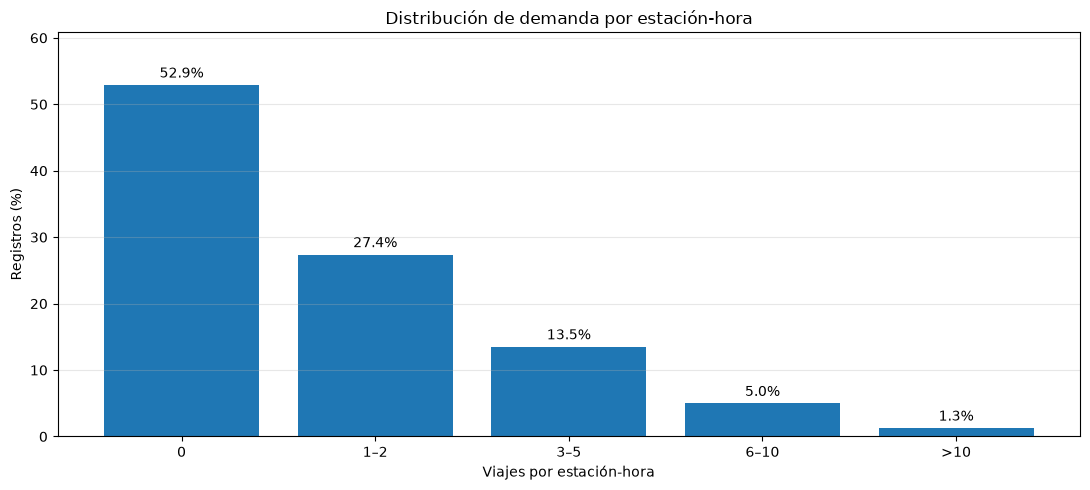

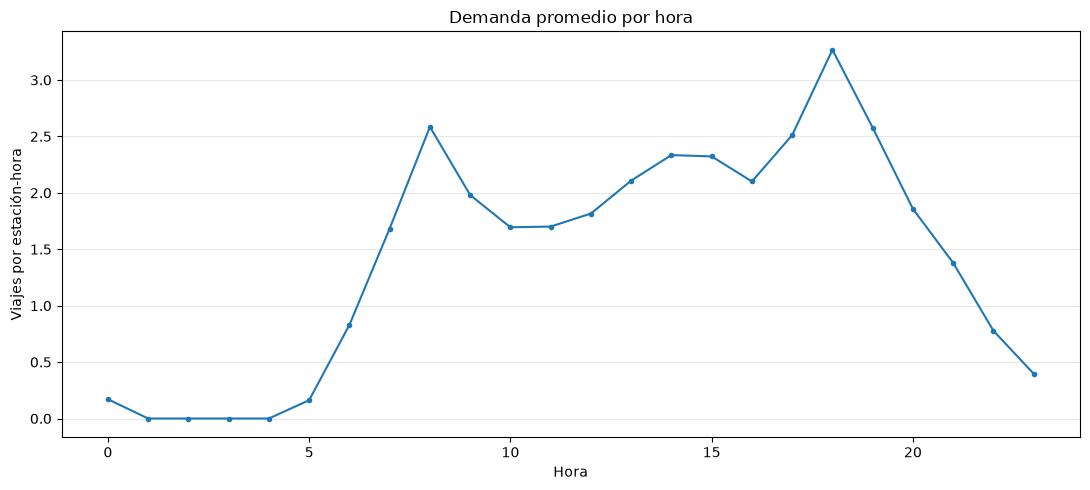

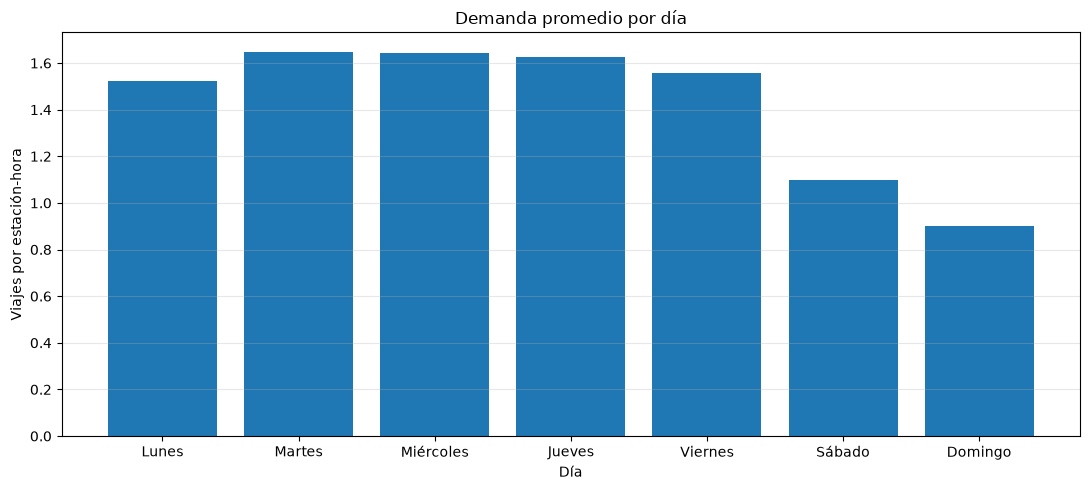

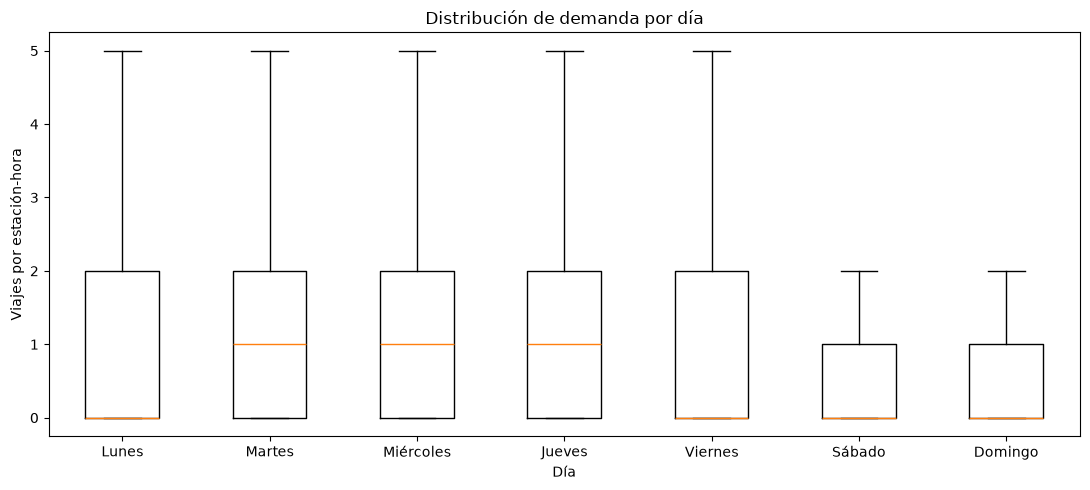

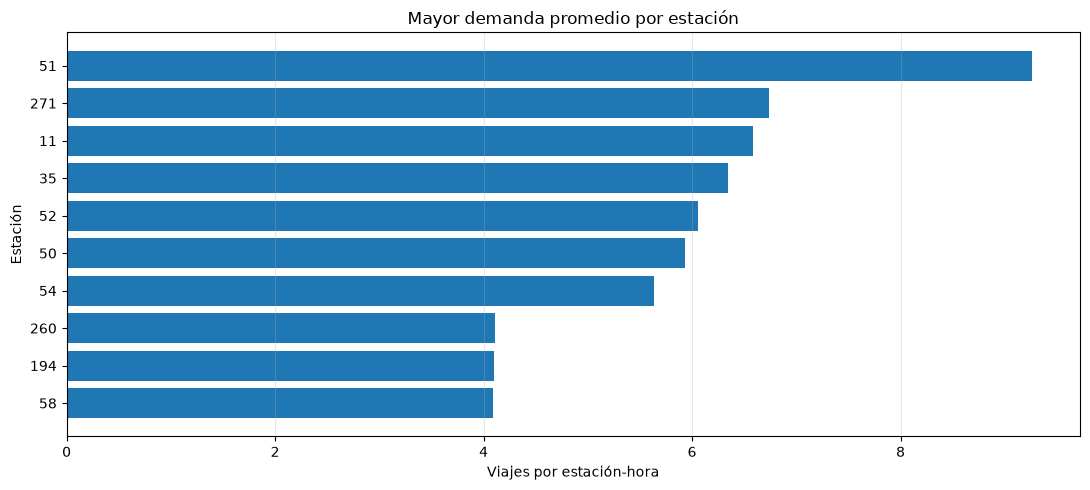

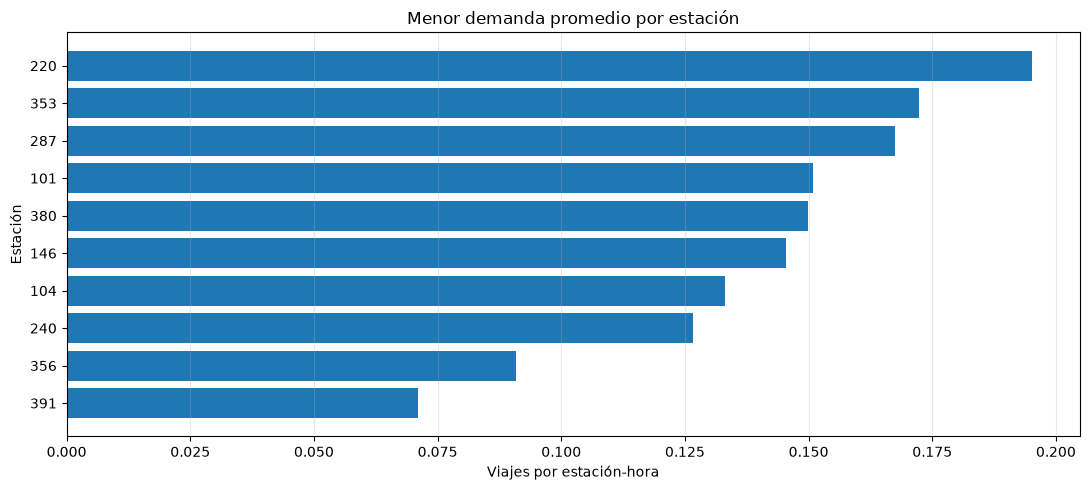

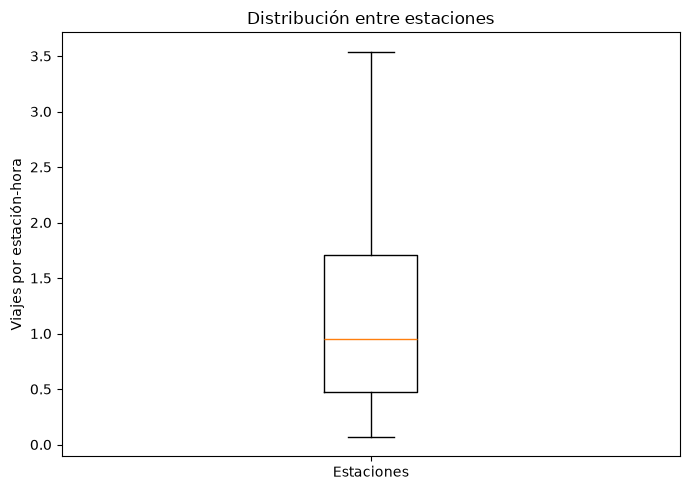

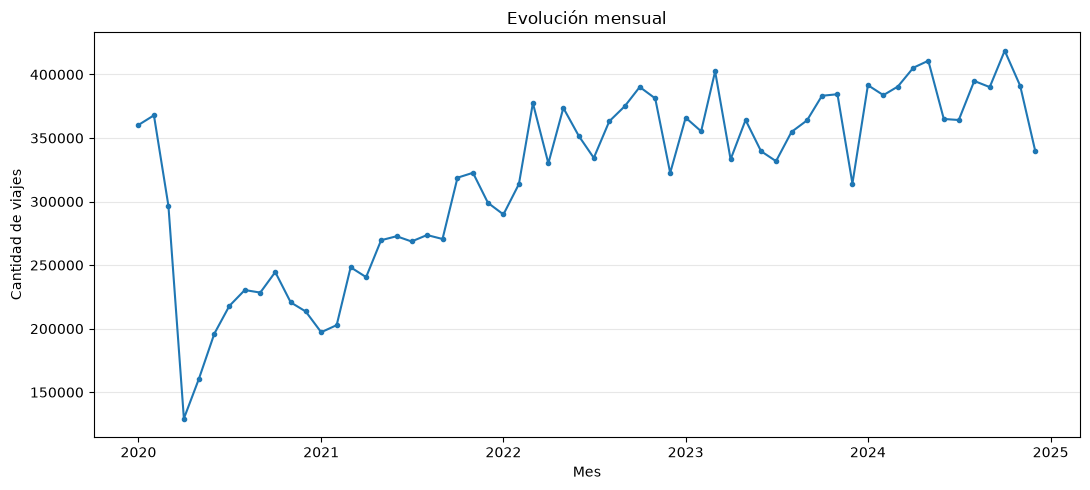

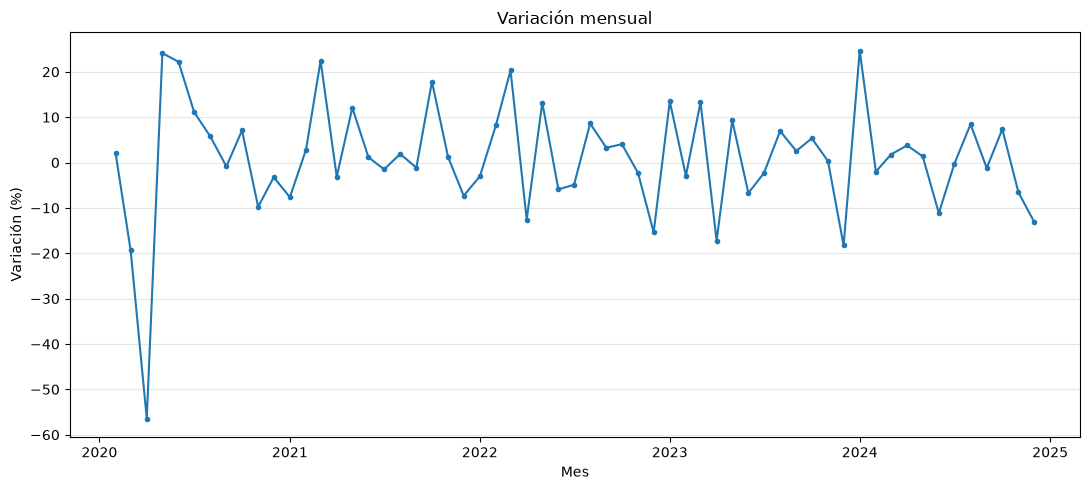

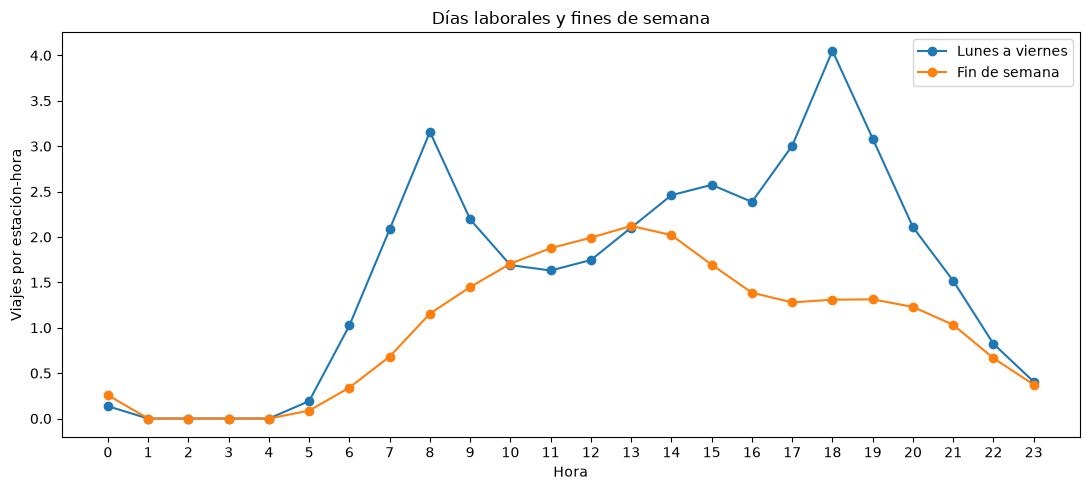

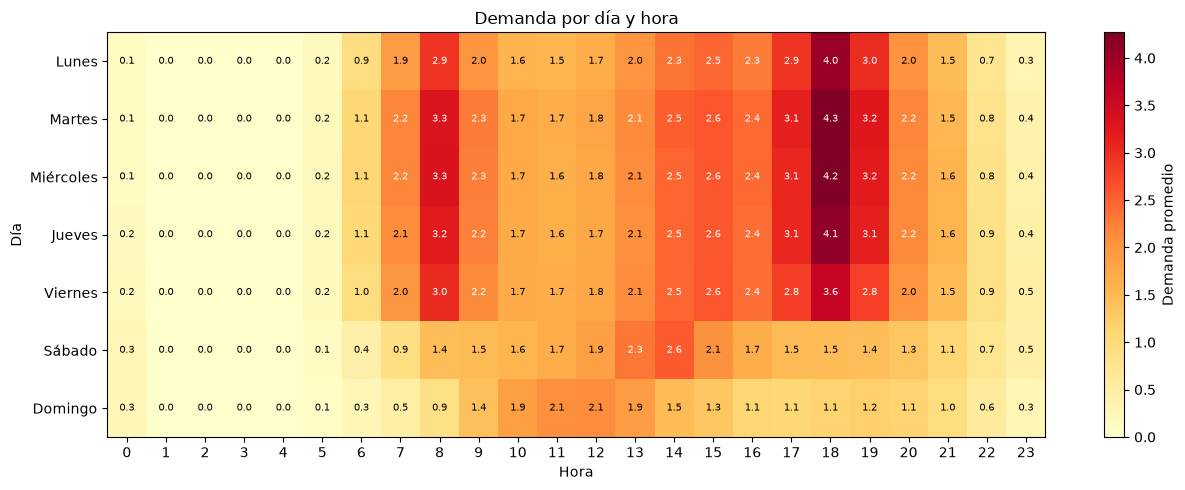

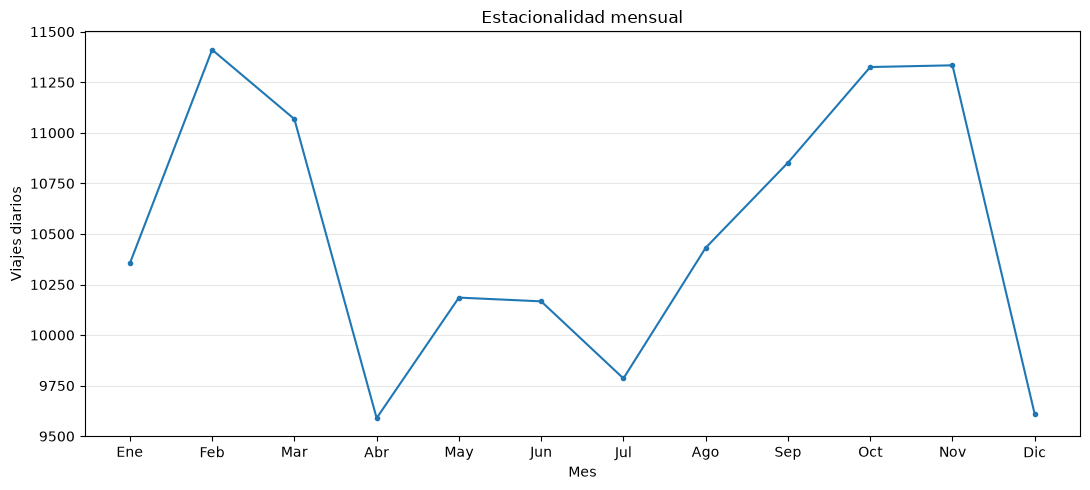

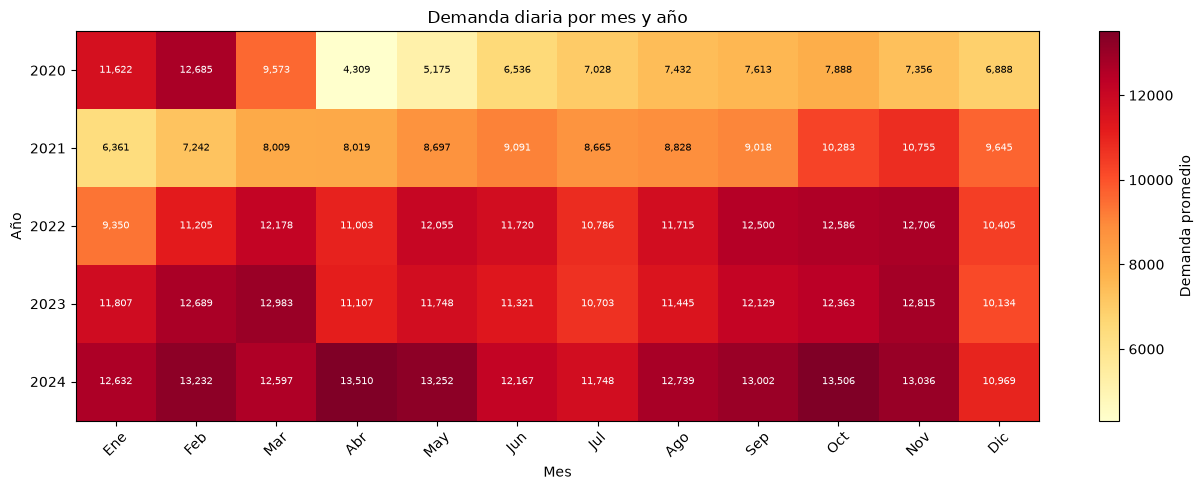

Atípicos: 838,081 de 13,445,045 (6.23%); límite IQR: 5.00


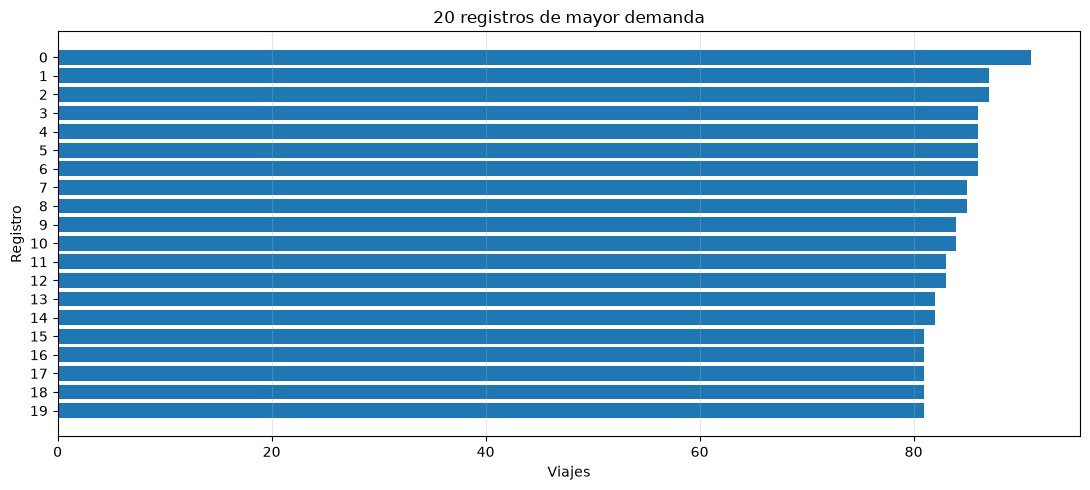

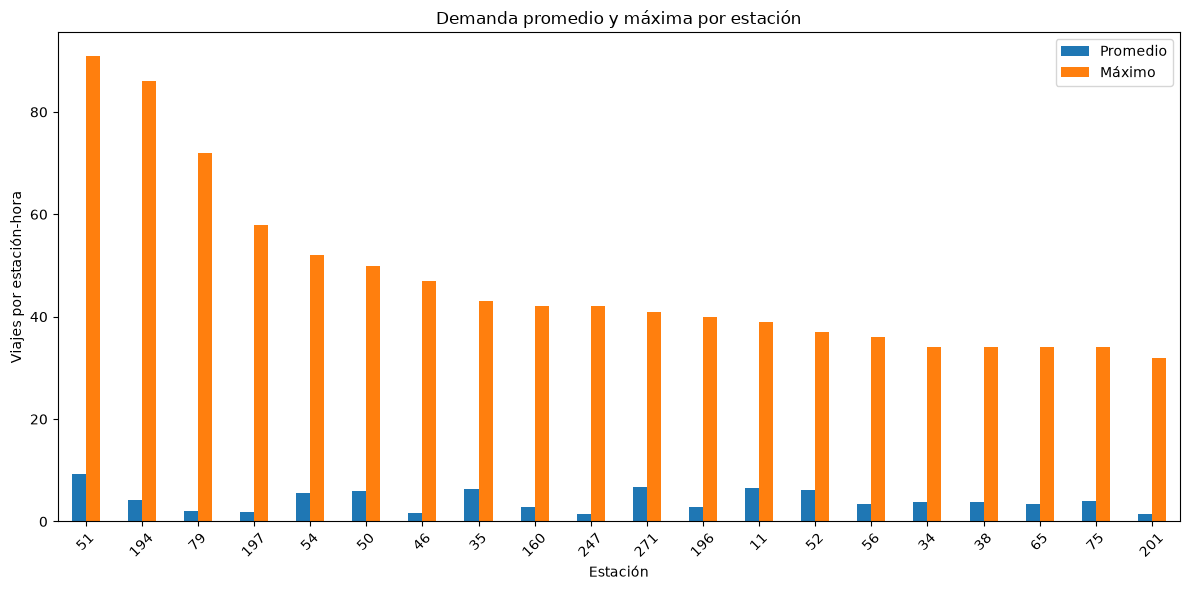

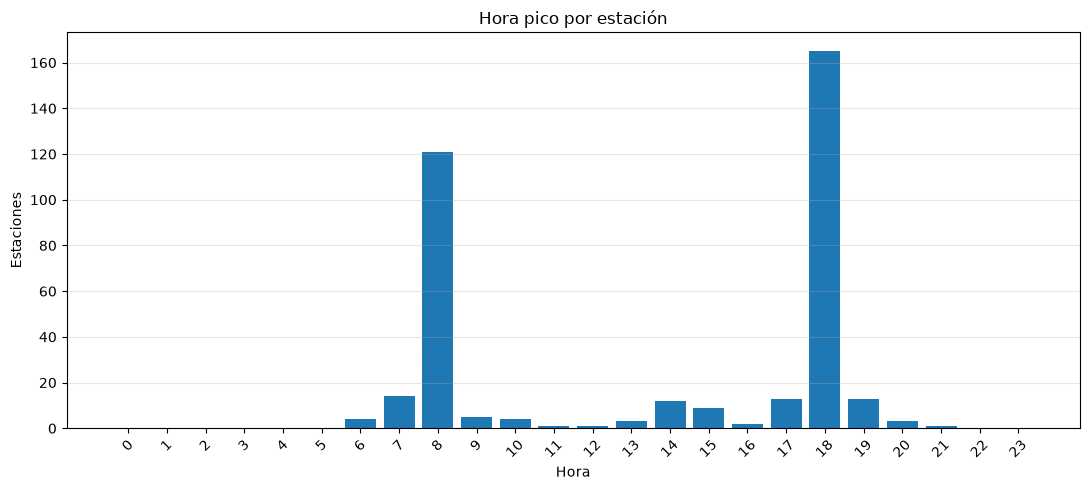

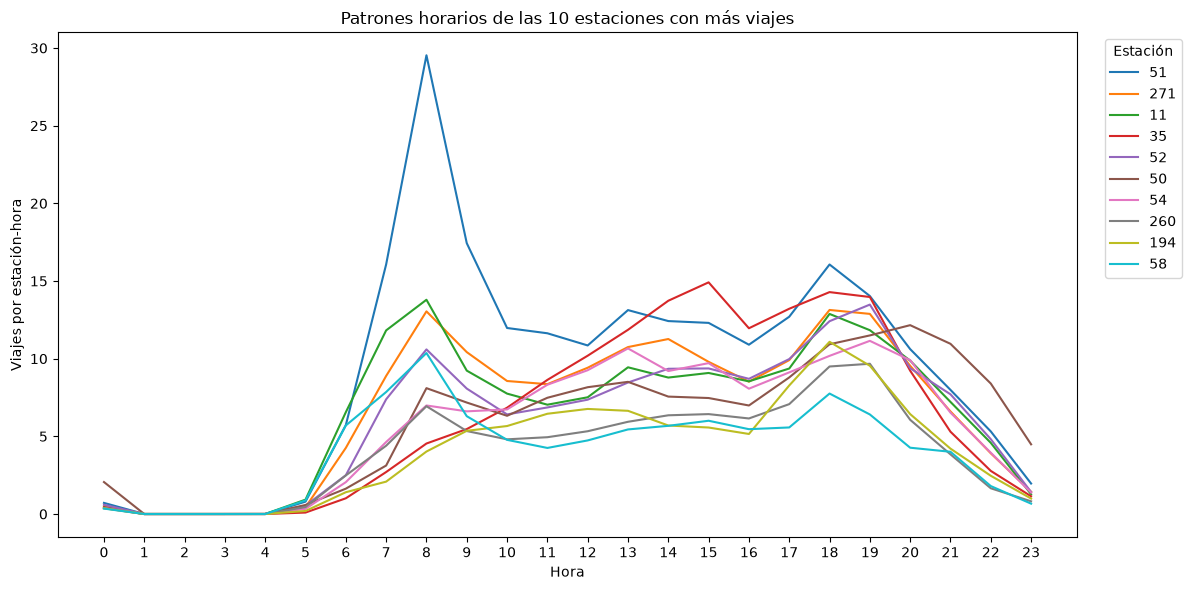

              Etapa   Segundos  Porcentaje etapas
      Normalización 155.700695          53.195584
        Lectura CSV  37.492223          12.809324
Acumulación horaria  33.975856          11.607948
         Limpieza B  24.156747           8.253221
  Escritura Parquet  17.550480           5.996171
          Variables  14.588474           4.984194
  Actualización IDs   4.135561           1.412926
    Demanda horaria   3.200186           1.093353
       Apertura CSV   1.894556           0.647280


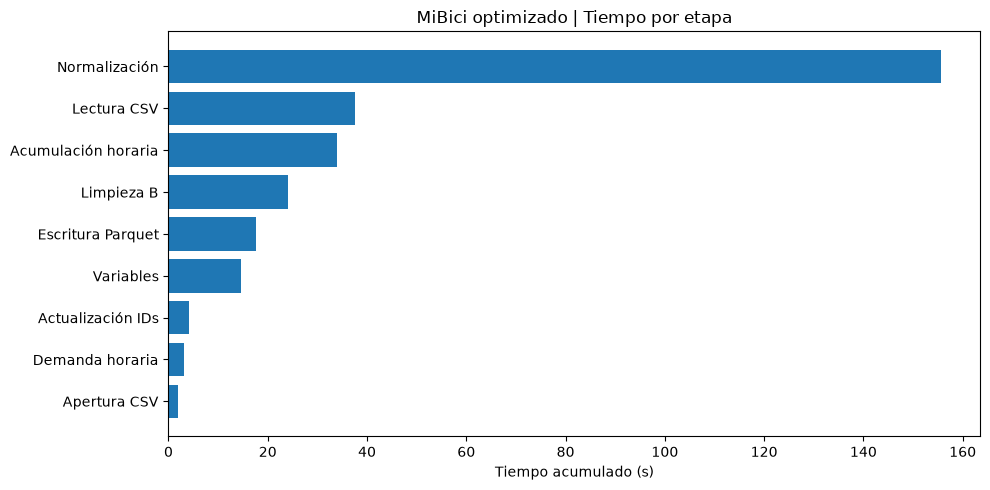

Cobertura completa: SÍ
Cobertura de MiBici optimizado: 81 CSV seleccionados
Ejecución de MLflow: 79abaa4de1914db6b8cdfab5459a03c1


In [36]:
def main(run_all_files: bool = RUN_ALL_FILES, chunk_size: int = CHUNK_SIZE,
         raw_dir: Path | None = None) -> dict:
    """Ejecutar el flujo completo de MiBici: pruebas, pipeline, separación, EDA, reportes y MLflow."""
    # 1. Rutas del proyecto
    project_root = locate_project_root(Path.cwd().resolve())
    data_dir = raw_dir if raw_dir is not None else project_root / 'data' / 'raw'
    report_base = project_root / 'reports' / 'validation'

    # 2. Pruebas con datos pequeños antes de tocar los CSV reales
    print(run_behavior_tests())
    print(run_integration_test())
    print(run_split_test())

    # 3. Inventario: los 81 CSV mensuales en orden cronológico
    files = discover_monthly_files(data_dir)
    selected_files = files if run_all_files else files[:2]

    # 4. Procesamiento por bloques: normalizar, limpiar, contar y guardar
    run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    results = process_dataset(
        selected_files, report_base / f'mibici_{run_id}', chunk_size,
        SAVE_TRIPS, run_all_files, RUN_LABEL
    )

    # 5. Dataset de modelado: horas sin viajes de cada estación en cero
    report_dir = results['report_dir']
    complete_station_hours(report_dir / 'hourly_demand.parquet',
                           report_dir / 'hourly_complete.parquet')

    # 6. Separación temporal: train, validation y test
    splits = split_dataset(report_dir / 'hourly_complete.parquet', report_dir / 'splits',
                           results['totals']['kept_rows'], run_all_files)
    results['splits'] = splits

    # 7. EDA con train: resúmenes en una sola lectura, tablas y gráficas
    summary, monthly_trips = prepare_eda(results, splits)
    tables = build_eda_tables(summary, monthly_trips)
    show_eda_tables(tables)
    save_eda_tables(tables, report_dir)
    figure_dir = report_dir / 'eda_figures'
    plot_demand_distribution(summary, output_dir=figure_dir)
    plot_demand_temporal(summary, monthly_trips, output_dir=figure_dir)
    plot_demand_extremes(summary, output_dir=figure_dir)

    # 8. Rendimiento y cobertura de la ejecución
    show_performance(results, RUN_LABEL)
    show_coverage(selected_files, run_all_files, RUN_LABEL)

    # 9. Registro de la ejecución en MLflow
    log_to_mlflow(results, splits, project_root, RUN_LABEL, chunk_size,
                  run_all_files, tables, monthly_trips)
    return results


if __name__ == '__main__':
    results = main()

## Referencias de apoyo

- OpenAI. (2026). *ChatGPT*. Apoyo en revisión y refactorización de código. https://chatgpt.com/
- Anthropic. (2026). *Claude*. Revisión del código repetido y de las pruebas de equivalencia de la versión optimizada. https://claude.ai/